# ПР1. Исследование качества набора данных для обучения глубокой модели

**Курс:** «Безопасность и доверенность систем ИИ». **Команда:** Андрусенко К.А., Синёв В.Е., Шестакова М.А., гр. 1379.

**Задача:** регрессия оценочной стоимости строительных работ `VALUATION` по разрешению на строительство в Лос-Анджелесе (цель — `log1p(VALUATION)`, основная метрика RMSLE, меньше — лучше). Сценарий применения: проверка адекватности оценки и поиск аномально заниженных или завышенных оценок.
**Модель:** FT-Transformer (собственная реализация на PyTorch), зафиксированный baseline.

Ноутбук **не пересчитывает** тяжёлые шаги: все таблицы и графики построены скриптом
`src/pr1_data_quality.py` (OOF-прогнозы, MinHash, MMD/C2ST, IsolationForest) и лежат в `reports/pr1/`.
Воспроизведение: `venv\Scripts\python src\pr1_data_quality.py` (кеши в `artifacts/`; пересчёт — `--force`).

**Доверительные интервалы.** Для долей — интервал Уилсона; для остальных метрик — bootstrap по объектам, B = 2000, seed = 42 (BCa при n ≤ 60 000, иначе percentile; метод указан в каждой таблице). Модель при bootstrap не переобучается. Датасет большой (сотни тысяч строк), поэтому интервалы узкие: статистическая значимость почти всегда есть, и обсуждать нужно **практическую** величину эффектов.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R, A = ROOT / "reports" / "pr1", ROOT / "artifacts"
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4g}".format)


def show(name, cols=None, n=None):
    df = pd.read_csv(R / f"{name}.csv")
    if cols:
        df = df[cols]
    display(df.head(n) if n else df)
    return df


def img(name, width=None):
    display(Image(filename=str(R / f"{name}.png"), width=width))

## 1. Описание набора данных

Источник — открытые данные г. Лос-Анджелес, Департамент строительства и безопасности (LADBS): два набора с одинаковой схемой
(разрешения 2010–2019 и 2020 – н. в.), выгрузка 30.10.2026. Используются только разрешения на здания трёх типов:
`Bldg-New`, `Bldg-Addition`, `Bldg-Alter/Repair` (остальные типы — Grading, Sign, Pool и др. — имеют другую природу оценки).

In [2]:
show("describe_dataset");

,Параметр,Значение
0,Источник,"Building and Safety - Building Permits Issued Between 2010 and 2019 (N) (dyxf-7hc4), https://data.lacity.org/City-Infrastructure-Service..."
1,Версия,"выгрузка 30.10.2026, данные обновлены 25.10.2026; файлы LA_BLDG_PERMITS_2010_2019_20261030.csv, LA_BLDG_PERMITS_2020_PRESENT_20261030.csv"
2,Тип задачи,"регрессия log1p(VALUATION); метрика RMSLE (меньше — лучше), доп. MdAPE, доля в ±25%"
3,Модальности,таблица (числовые и категориальные признаки) + короткий текст WORK_DESC
4,Строк в наборах,"953,873 (dyxf-7hc4: 533,366, pi9x-tg5x: 420,507)"
5,Три типа Bldg (рабочая совокупность),"760,227"
6,Исключено: VALUATION пусто / ≤ 0,"40 / 50,513"
7,Исключено: дубли без учёта ID,365
8,Строк для обучения,"709,309"
9,Признаки модели,"12 числовых, 16 категориальных, текст → SVD(64); всего токенов 30"


In [3]:
cfg = json.loads((A / "config.json").read_text(encoding="utf-8"))
met = json.loads((A / "baseline_metrics.json").read_text(encoding="utf-8"))["test"]
display(Markdown(
    f"**Baseline (зафиксирован):** {cfg['model']['arch']}, {cfg['model']['n_params']:,} параметров, "
    f"лучшая эпоха {cfg['training']['best_epoch']}, устройство {cfg['device']}.  \n"
    f"Test: RMSLE {met['rmsle']['estimate']:.3f} [{met['rmsle']['low']:.3f}; {met['rmsle']['high']:.3f}] ({met['rmsle']['method']}), "
    f"MdAPE {met['mdape_pct']['estimate']:.1f}% [{met['mdape_pct']['low']:.1f}; {met['mdape_pct']['high']:.1f}], "
    f"доля в ±25% {met['within25_wilson']['estimate']:.3f} [{met['within25_wilson']['low']:.3f}; {met['within25_wilson']['high']:.3f}] (Уилсон)."))
show("describe_features");

**Baseline (зафиксирован):** FT-Transformer (pre-LN, ReGLU, [CLS]-голова, текст — отдельный токен), 1,481,857 параметров, лучшая эпоха 4, устройство cuda:AMD Radeon RX 7700 XT.  
Test: RMSLE 1.031 [1.024; 1.040] (BCa), MdAPE 48.3% [47.9; 48.7], доля в ±25% 0.282 [0.280; 0.285] (Уилсон).

,признак,тип,преобразование
0,square_footage,числовой,log
1,height,числовой,log
2,du_changed,числовой,slog
3,adu_changed,числовой,slog
4,lat,числовой,none
5,lon,числовой,none
6,issue_year,числовой,none
7,issue_month,числовой,none
8,issue_dow,числовой,none
9,issue_doy,числовой,none


,группа,столбец
0,id,PERMIT_NBR
1,id,PIN_NBR
2,id,APN
3,id,USE_CODE
4,id,PERMIT_GROUP
5,id,REFRESH_TIME
6,id,GEOLOCATION
7,address,PRIMARY_ADDRESS
8,future,STATUS_DESC
9,future,STATUS_DATE


,часть,n,min,p1,p5,p25,медиана,p75,p95,p99,max,среднее,log1p: среднее,log1p: std,log1p: асимметрия
0,all,709309,1,501,501,3900,1e+04,4e+04,3.113e+05,1.25e+06,1.967e+09,1.398e+05,9.401,1.865,0.3559
1,train,496596,1,501,501,4000,1e+04,4e+04,3.25e+05,1.307e+06,5.838e+08,1.468e+05,9.411,1.857,0.3877
2,val,106421,1,501,501,3750,1e+04,4.5e+04,2.64e+05,1e+06,2.798e+08,1.086e+05,9.372,1.863,0.2565
3,test,106292,1,501,501,3600,9600,4.5e+04,3.25e+05,1.2e+06,1.967e+09,1.381e+05,9.388,1.902,0.3125


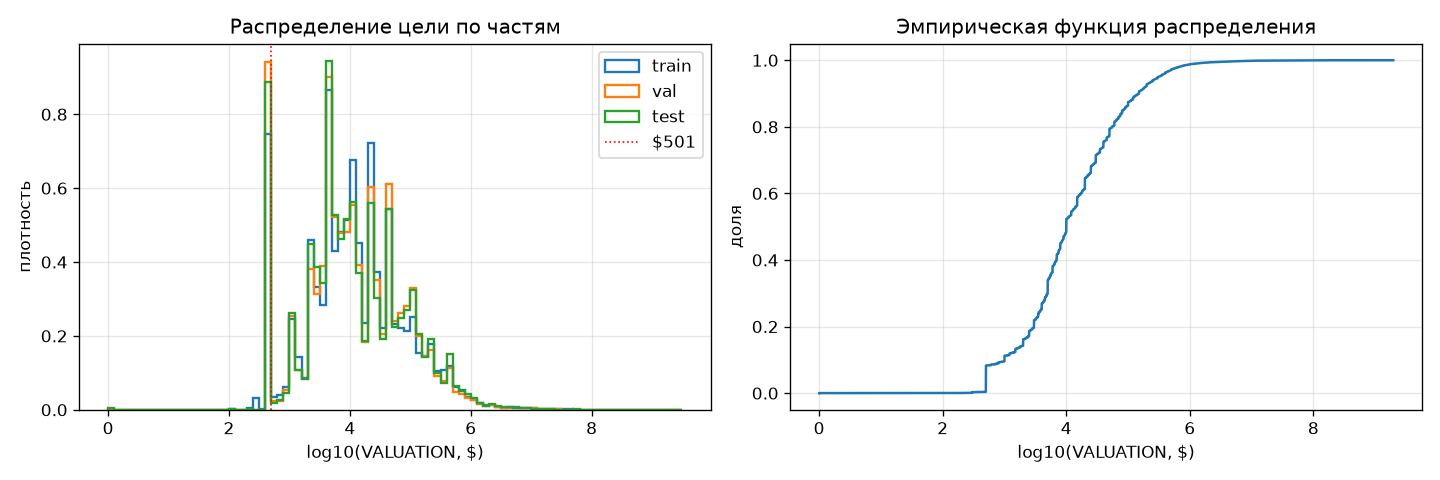

In [4]:
show("describe_excluded");
show("describe_target");
img("target_distribution")

**Интерпретация.**
* Модальности: таблица (12 числовых и 16 категориальных признаков после отбора) и короткий текст `WORK_DESC` (медиана ≈ 130 символов), который подаётся в модель одним токеном (TF-IDF → SVD(64)).
* Из признаков исключены идентификаторы (PERMIT_NBR, APN, PIN), адрес объекта, признаки «из будущего» относительно момента выдачи (STATUS_DESC, STATUS_DATE, COFO_DATE), столбцы с > 99% пропусков (JUNIOR_ADU) и константы (Solar).
* Цель сильно скошена: от $1 до ≈ $2 млрд, медиана ≈ $10 000. В log-шкале распределение близко к симметричному (асимметрия ≈ 0,36), но с **пиком на $501** (1-й и 5-й перцентили равны $501) — это служебное значение, см. раздел 7.
* Split хронологический (70/15/15 по дате выдачи): test описывает «будущее» относительно train — это сознательный выбор, приближающий оценку к реальному применению.

## 2. Полнота

Пропуски считаются по исходным столбцам в рабочей совокупности (три типа Bldg, 760 227 строк); отдельно — по столбцам, из которых строятся признаки модели.

In [5]:
show("completeness_objects");
show("completeness_columns", n=20);

,метрика,value,ci_low,ci_high,ci_method,n
0,доля пропущенных ячеек в используемых признаках,0.2371,0.2369,0.2372,percentile,760227
1,доля объектов хотя бы с одним пропуском в используемых признаках,0.9994,0.9993,0.9994,wilson,760227
2,доля пропусков SQUARE_FOOTAGE у Bldg-New,0.02085,0.01973,0.02203,wilson,59180


,столбец,k_missing,value,ci_low,ci_high,ci_method,n,используется_в_модели
0,JUNIOR_ADU,755634,0.994,0.9938,0.9941,wilson,760227,False
1,ADU_CHANGED,707314,0.9304,0.9298,0.931,wilson,760227,True
2,DU_CHANGED,666565,0.8768,0.8761,0.8775,wilson,760227,True
3,HEIGHT,654766,0.8613,0.8605,0.8621,wilson,760227,True
4,COFO_DATE,626981,0.8247,0.8239,0.8256,wilson,760227,False
5,HL,607146,0.7986,0.7977,0.7995,wilson,760227,True
6,CONSTRUCTION,561301,0.7383,0.7373,0.7393,wilson,760227,True
7,SQUARE_FOOTAGE,559502,0.736,0.735,0.737,wilson,760227,True
8,SUBMITTED_DATE,345583,0.4546,0.4535,0.4557,wilson,760227,True
9,CNC,37484,0.04931,0.04882,0.0498,wilson,760227,True


,столбец,Bldg-Addition,Bldg-Alter/Repair,Bldg-New,1 or 2 Family Dwelling,Apartment,Commercial
0,SQUARE_FOOTAGE,0.003018,0.9075,0.02085,0.6831,0.9149,0.8065
1,HEIGHT,0.6075,0.9797,0.0006421,0.8246,0.9562,0.9389
2,CONSTRUCTION,0.0001973,0.9128,0.0002873,0.6855,0.9163,0.8096
3,DU_CHANGED,0.5249,0.9684,0.437,0.8401,0.9366,0.9892
4,ADU_CHANGED,0.7981,0.9632,0.7823,0.9059,0.9766,0.9995
5,SUBMITTED_DATE,0.0008821,0.5619,0.0004055,0.5,0.5608,0.1369
6,HL,0.7961,0.7992,0.7964,0.7522,0.8951,0.9206
7,CNC,0.05033,0.04573,0.08503,0.05246,0.05027,0.03362


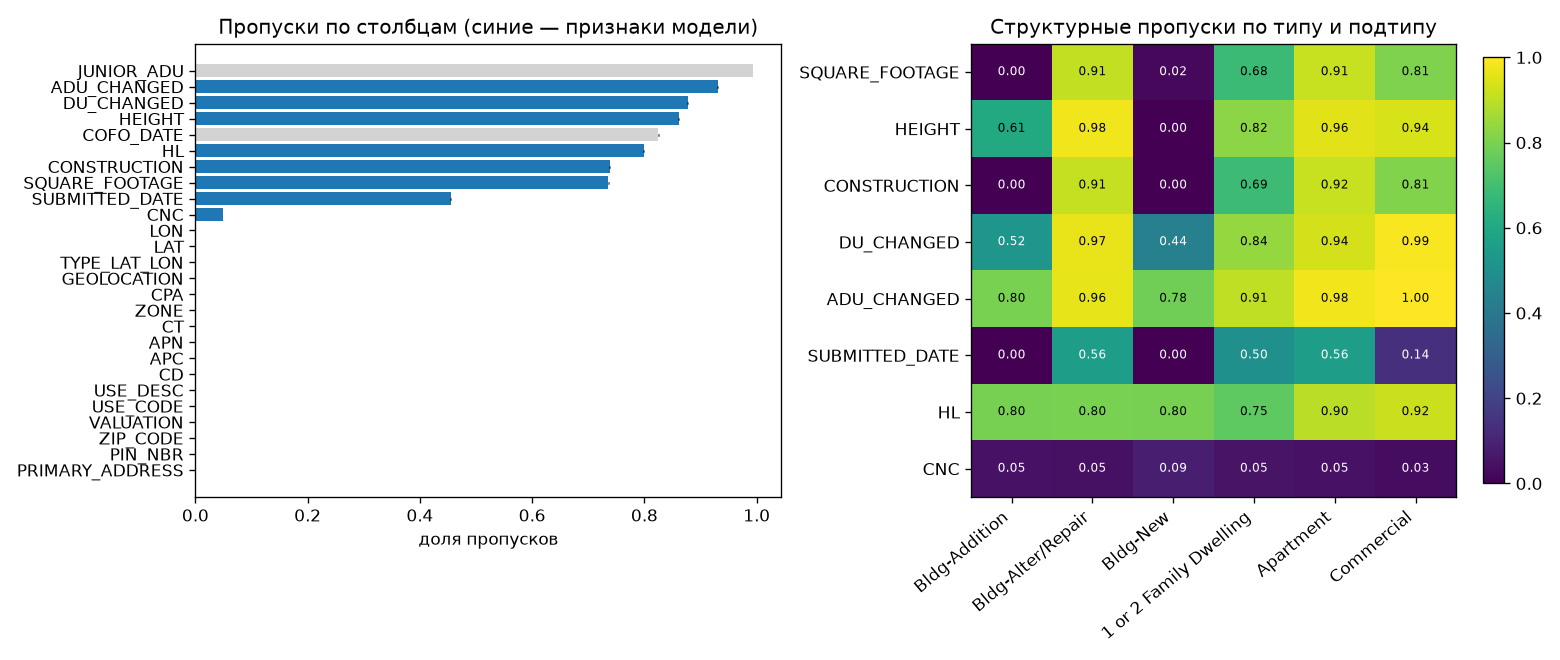

In [6]:
show("completeness_by_type");
img("completeness")

**Интерпретация.**
* Доля пропущенных ячеек в признаках модели ≈ **23,7%**, и практически **у каждого объекта (99,9%) есть хотя бы один пропуск** — модель обязана работать с неполными данными (в FT-Transformer для каждого числового признака есть обучаемый эмбеддинг «пропуск»).
* Пропуски **структурные**, а не случайные: площадь, высота и тип конструкции почти всегда заполнены у `Bldg-New` (пропуск площади 2,1% [2,0; 2,2]) и `Bldg-Addition`, но отсутствуют у ≈ 91–98% `Bldg-Alter/Repair` — а это 80% данных. Для ремонтов модель вынуждена опираться на текст и категории.
* `SUBMITTED_DATE` пропущена у ≈ 45% строк стабильно по годам. Это тоже структурный пропуск: у экспресс-разрешений (`Business Unit = Express Permit`, 45% данных, выдаются в день обращения) дата подачи не заполняется никогда, и на них приходится 98% всех пропусков этого поля.
* Следствие для ПР2: шум «пропуски» в площади/высоте затронет в основном New/Addition; у Alter/Repair эти признаки и так пусты.

## 3. Валидность

Проверяются формат, допустимые диапазоны и правила предметной области. Для проверок условных признаков знаменатель — строки, где проверка применима (например, только заполненная площадь).

,check,тип,k,знаменатель,value,ci_low,ci_high
0,VALUATION пусто,метка,40,760227,5.262e-05,3.864e-05,7.164e-05
1,VALUATION ≤ 0,метка,50513,760227,0.06644,0.06589,0.06701
2,SQUARE_FOOTAGE ≤ 0 (из заполненных),диапазон,32769,200725,0.1633,0.1616,0.1649
3,SQUARE_FOOTAGE ≤ 0 у Bldg-New (из заполненных),диапазон,3530,57946,0.06092,0.059,0.0629
4,HEIGHT ≤ 0 (из заполненных),диапазон,21,105461,0.0001991,0.0001303,0.0003044
5,HEIGHT > 1100 футов (выше самого высокого здания LA),диапазон,45,105461,0.0004267,0.0003189,0.0005709
6,DU_CHANGED > 2 у «1 or 2 Family Dwelling»,предметная область,11,85276,0.000129,7.203e-05,0.000231
7,DU_CHANGED < 0 у Bldg-New,предметная область,0,33320,0,0,0.0001153
8,ISSUE_DATE < SUBMITTED_DATE,даты,2,414644,4.823e-06,1.323e-06,1.759e-05
9,STATUS_DATE < ISSUE_DATE,даты,375,760227,0.0004933,0.0004458,0.0005458


,метрика,value,ci_low,ci_high,ci_method,n
0,доля объектов с ≥ 1 нарушением,0.1404,0.1397,0.1412,wilson,760227
1,то же среди VALUATION > 0,0.07922,0.07859,0.07985,wilson,709674


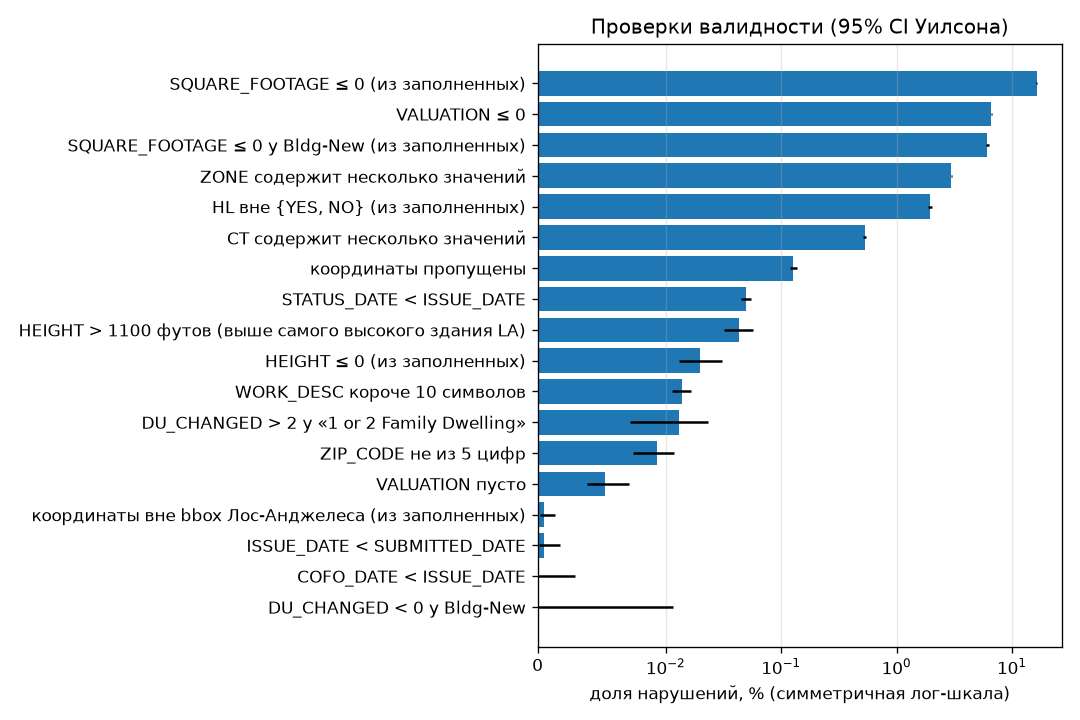

In [7]:
show("validity", cols=["check", "тип", "k", "знаменатель", "value", "ci_low", "ci_high"]);
show("validity_overall");
img("validity")

**Интерпретация.**
* **14,0% [14,0; 14,1]** объектов нарушают хотя бы одно правило; среди строк с положительной оценкой — 7,9%.
* Главные нарушения:
  * `VALUATION ≤ 0` — **6,6%** (невалидная метка; строки исключены из обучения);
  * **площадь ≤ 0 у 16,3% заполненных значений** (6,1% даже у нового строительства): ноль используется как «не указано». Это шум в одном из самых информативных признаков, и препроцессор не отличает его от реальной площади (ноль ≠ пропуск);
  * форматные проблемы: несколько значений через запятую в ZONE (3,0%) и CT (0,5%), нестандартные значения HL (`Yes`, `EXEMPT…` — 2,0% заполненных).
* Редкие, но грубые ошибки: высота > 1100 футов (45 строк, максимум 41 033), координаты вне Лос-Анджелеса (4 строки, широта ≈ 720), `STATUS_DATE < ISSUE_DATE` (375).
* Следствие для ПР3: ограничения валидности (validity constraints) для состязательных примеров нужно задавать **по правилам предметной области** (площадь > 0, высота ≤ 1100, DU_CHANGED ≤ 2 для «1 or 2 Family»), а не по «как в train» — в данных уже 14% нарушений.

## 4. Уникальность: точные и близкие дубликаты

* Точные дубли — совпадение всех столбцов; дубли без ID — всех, кроме `PERMIT_NBR` и `REFRESH_TIME`.
* Близкие дубли — тот же участок (APN), похожий текст (оценка Jaccard по MinHash, 64 перестановки, символьные 5-граммы, порог 0,9) и стоимость, отличающаяся не более чем на 10%. Учитывается более поздняя строка пары.

In [8]:
show("uniqueness", cols=["check", "совокупность", "k", "n", "value", "ci_low", "ci_high"]);
show("uniqueness_supplemental_501");
show("uniqueness_near_dup_examples", n=8);

,check,совокупность,k,n,value,ci_low,ci_high
0,точные дубли (все столбцы),три типа Bldg,0,760227,0,0,5.053e-06
1,"дубли без учёта ID (PERMIT_NBR, REFRESH_TIME)",три типа Bldg,467,760227,0.0006143,0.0005611,0.0006726
2,повторы PERMIT_NBR,три типа Bldg,0,760227,0,0,5.053e-06
3,совпадают участок + текст + стоимость + тип,три типа Bldg,13978,760227,0.01839,0.01809,0.01869
4,"близкие дубли: тот же APN, Jaccard ≥ 0.9, стоимость ±10%",строки для обучения,2675,709309,0.003771,0.003631,0.003917
5,"близкий текст на том же APN (Jaccard ≥ 0.9, без условия на стоимость)",строки для обучения,13192,709309,0.0186,0.01829,0.01892
6,дополнительные разрешения («Supplemental…» в описании),строки для обучения,75820,709309,0.1069,0.1062,0.1076


,check,k,value,ci_low,ci_high,ci_method,n
0,$501 среди дополнительных разрешений,34494,0.4549,0.4514,0.4585,wilson,75820
1,$501 среди остальных,20333,0.0321,0.03167,0.03253,wilson,633489


,PERMIT_NBR_a,PERMIT_NBR_b,APN,jaccard,VALUATION_a,VALUATION_b,ISSUE_a,ISSUE_b,WORK_DESC_a,WORK_DESC_b
0,25016-90000-10954,26016-90000-23029,2679001006,0.9531,6300,5800,2025-04-09,2026-08-27,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over new solid sheathing 21 Squares. Class A ro...,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over existing solid sheathing 29 Squares. Class...
1,25016-90000-22599,26016-90000-29035,4302004011,0.9219,6900,7200,2025-07-23,2026-10-19,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over new solid sheathing 23 Squares. Class A ro...,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over existing solid sheathing 36 Squares. Class...
2,26016-90000-10986,25016-90000-10435,2316023003,1,4200,4200,2026-04-24,2025-04-04,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over existing solid sheathing 21 Squares. Class...,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over existing solid sheathing 21 Squares. Class...
3,22016-90000-12949,20016-90000-23388,2748010041,1,5600,5600,2022-04-27,2020-09-17,Reroof with 28 sqrs COMP SHINGLE roofing. Existing solid sheathing.Re-roof with Class A or B material weighing less than 6 pounds per sq...,Reroof with 28 sqrs COMP SHINGLE roofing. Existing solid sheathing.Re-roof with Class A or B material weighing less than 6 pounds per sq...
4,24016-90000-28968,26016-90000-16590,4311001024,1,2500,2500,2024-09-10,2026-06-23,Add sill plate anchor bolts and plywood to cripple walls (if existing) per LA City Standard Plan #1; no foundation replacement (Earthqua...,Add sill plate anchor bolts and plywood to cripple walls (if existing) per LA City Standard Plan #1; no foundation replacement (Earthqua...
5,23016-90000-43161,24016-90000-14676,2040018016,0.9531,6000,5700,2023-12-06,2024-05-02,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over existing solid sheathing 30 Squares. Class...,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over new solid sheathing 19 Squares. Class A ro...
6,23016-90000-12246,23016-90000-32538,2136016006,1,5600,5600,2023-04-19,2023-09-21,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over existing solid sheathing 28 Squares. Class...,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over existing solid sheathing 28 Squares. Class...
7,13016-90000-17958,14016-90000-19544,4423017020,1,3760,3460,2013-08-30,2014-09-26,Add sill plate anchors bolts and cripple wall plywood per L.A. City Std. Plan #1; no foundation replacement (EQ hazard reduction per Cha...,Add sill plate anchors bolts and cripple wall plywood per L.A. City Std. Plan #1; no foundation replacement (EQ hazard reduction per Cha...


**Интерпретация.**
* Точных дублей нет (PERMIT_NBR уникален); **дублей без ID — 0,061%** (467 строк в рабочей совокупности; удалены до разбиения).
* **Близкие дубли — 0,38% [0,36; 0,39]**. Ручной просмотр примеров показывает, что это в основном **повторные типовые разрешения на тот же дом** (перекрытие кровли, сейсмоусиление по шаблону) с интервалом от нескольких месяцев до нескольких лет — вероятно, повторная выдача после истечения срока. Это не технические дубли, но для модели такие объекты почти идентичны.
* Важная структурная находка: **10,7% разрешений — дополнительные** («Supplemental to …») и ссылаются на основное разрешение. **У 45,5% из них стоимость = $501**, против 3,2% у остальных. Значит, $501 — в первую очередь служебная стоимость дополнительных и административных разрешений.

## 5. Train-test leakage

* «Точная копия входа» — совпадение всех исходных полей, из которых строятся признаки, кроме абсолютных дат (дата выдачи заменена сроком рассмотрения), и нормализованного текста.
* Близкий дубль — пара из раздела 4, где одна строка в train, другая в val/test.
* Общие участки — участок (APN) объекта val/test встречается в train.

In [9]:
show("leakage", cols=["часть", "check", "k", "n", "value", "ci_low", "ci_high"]);
show("leakage_excluded_features");

,часть,check,k,n,value,ci_low,ci_high
0,val,точная копия входа модели в train (без абсолютного времени),87,106421,0.0008175,0.0006629,0.001008
1,val,точная копия входа и метки в train,26,106421,0.0002443,0.0001667,0.000358
2,val,"близкий дубль в train (APN + Jaccard ≥ 0,9)",1411,106421,0.01326,0.01259,0.01396
3,val,близкий дубль в train + стоимость ±10%,249,106421,0.00234,0.002067,0.002649
4,val,участок (APN) встречается в train,51441,106421,0.4834,0.4804,0.4864
5,test,точная копия входа модели в train (без абсолютного времени),19,106292,0.0001788,0.0001144,0.0002792
6,test,точная копия входа и метки в train,2,106292,1.882e-05,5.16e-06,6.861e-05
7,test,"близкий дубль в train (APN + Jaccard ≥ 0,9)",923,106292,0.008684,0.008143,0.009259
8,test,близкий дубль в train + стоимость ±10%,135,106292,0.00127,0.001073,0.001503
9,test,участок (APN) встречается в train,45633,106292,0.4293,0.4263,0.4323


,группа,столбец
0,id,PERMIT_NBR
1,id,PIN_NBR
2,id,APN
3,id,USE_CODE
4,id,PERMIT_GROUP
5,id,REFRESH_TIME
6,id,GEOLOCATION
7,address,PRIMARY_ADDRESS
8,future,STATUS_DESC
9,future,STATUS_DATE


**Интерпретация.**
* Утечка объектов между частями **пренебрежимо мала**: точная копия входа модели в train у 0,02% test (19 строк), с той же меткой — 2 строки; близкий дубль с близкой стоимостью — 0,13%. Хронологический split и удаление дублей сработали: завышения качества на test из-за копий нет.
* Признаки «из будущего» (статус, дата статуса, дата CofO) исключены — утечки цели через них нет.
* Но **у 42,9% [42,6; 43,2] test-объектов участок встречается в train** (у val — 48,3%). Для качества модели это нормально (на участке со временем выдаются новые разрешения), но **для ПР4 это принципиально**: если privacy unit — участок или владелец, то выборки members и non-members не независимы.

## 6. Баланс

Задача — регрессия, поэтому баланс оценивается по бинам цели (порядок величины стоимости) и по составу подгрупп.

,часть,n,imbalance_ratio (max/min бин),энтропия (норм.),доля < $1k,доля $1k–10k,доля $10k–100k,доля $100k–1M,доля $1M–10M,доля ≥ $10M
0,train,496596,201.3,0.7105,0.09249,0.3841,0.3891,0.1211,0.0112,0.001933
1,val,106421,281.4,0.7164,0.1048,0.3913,0.3685,0.1247,0.009303,0.001391
2,test,106292,334,0.7201,0.09867,0.4084,0.3456,0.1348,0.01122,0.001223


,check,k,value,ci_low,ci_high,ci_method,n,часть
0,"VALUATION > p99(train) = $1,307,150",4966,0.01,0.009727,0.01028,wilson,496596,train
1,"VALUATION > p99(train) = $1,307,150",822,0.007724,0.007216,0.008268,wilson,106421,val
2,"VALUATION > p99(train) = $1,307,150",956,0.008994,0.008444,0.00958,wilson,106292,test


,признак,chi2,p_value,dof
0,PERMIT_TYPE,666.1,7.471e-143,4
1,PERMIT_SUB_TYPE,4346,0,4


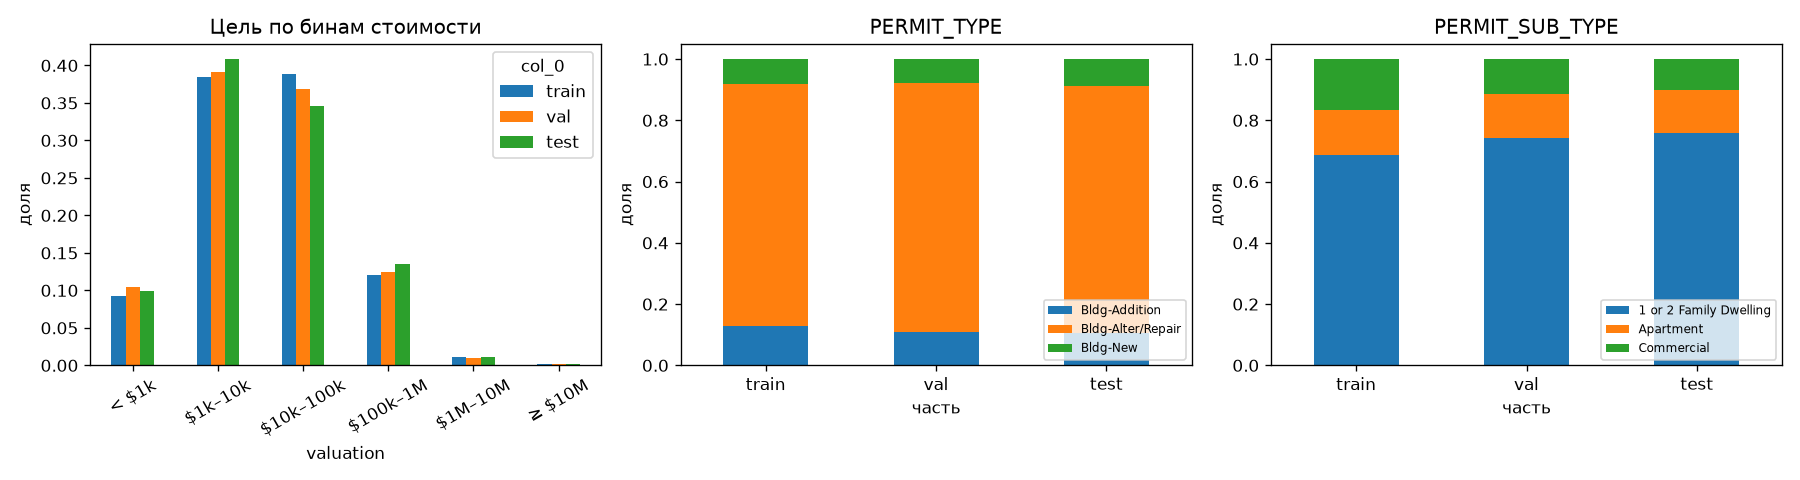

In [10]:
show("balance_target_bins");
show("balance_tail");
show("balance_subgroups_chi2");
img("balance")

**Интерпретация.**
* Распределение по бинам умеренно несбалансировано: нормированная энтропия **0,71**; **imbalance ratio = 201** (train) за счёт редкого хвоста ≥ $10M (0,19% train). В test IR ещё выше (334): дорогих объектов меньше.
* Доля объектов дороже p99 train ($1,31 млн): 1,00% в train, 0,77% в val, 0,90% в test — хвост устойчив, но мал, поэтому качество на дорогих объектах оценивается с большой неопределённостью.
* Состав подгрупп **меняется во времени** (χ², p ≈ 0): доля `Commercial` падает с 16,5% в train до 10,1% в test. Метрики, усреднённые по test, относятся к другому составу, чем train, — это нужно учитывать при сравнении.

## 7. Качество меток

**Метод (confident learning для регрессии).** Для train получены **out-of-fold прогнозы**: 5-fold CV, в каждом фолде — FT-Transformer с гиперпараметрами baseline (ранняя остановка по val, как у baseline). Для val и test используются прогнозы baseline (она не видела эти объекты). Остаток $r = \log(1+y) - \hat{y}$; метка считается подозрительной при $|z| > 3{,}5$, где $z = 0{,}6745\,(r - \mathrm{median}\,r)/\mathrm{MAD}(r)$ (Iglewicz–Hoaglin).
Дополнительно: доля $|r| > \ln 10$ (ошибка больше чем в 10 раз), `cleanlab.regression` label quality score (метод OUTRE; из-за памяти — 100 соседей вместо 0,5·n), частоты служебных значений и ручной разбор 20 худших.

In [11]:
show("labels_oof_quality");
show("labels_suspicious", cols=["часть", "прогноз", "check", "k", "n", "value", "ci_low", "ci_high"]);

,метрика,value,ci_low,ci_high,ci_method,n
0,RMSLE OOF (train),0.9419,0.9387,0.9452,percentile,496596
1,"MdAPE OOF (train), %",42.48,42.32,42.62,percentile,496596


,часть,прогноз,check,k,n,value,ci_low,ci_high
0,train,OOF 5-fold,|robust z| > 3.5,14216,496596,0.02863,0.02817,0.02909
1,train,OOF 5-fold,|r| > ln 10 (ошибка > 10 раз),15006,496596,0.03022,0.02975,0.0307
2,train,OOF 5-fold,из них прогноз выше метки (метка занижена?),6784,14216,0.4772,0.469,0.4854
3,train,OOF 5-fold,"|robust z| > 3.5, Bldg-New",319,41075,0.007766,0.006962,0.008662
4,train,OOF 5-fold,"|robust z| > 3.5, Bldg-Addition",890,63014,0.01412,0.01323,0.01508
5,train,OOF 5-fold,"|robust z| > 3.5, Bldg-Alter/Repair",13007,392507,0.03314,0.03258,0.0337
6,val,baseline,|robust z| > 3.5,3233,106421,0.03038,0.02937,0.03143
7,val,baseline,|r| > ln 10 (ошибка > 10 раз),3792,106421,0.03563,0.03453,0.03676
8,val,baseline,из них прогноз выше метки (метка занижена?),1179,3233,0.3647,0.3483,0.3814
9,val,baseline,"|robust z| > 3.5, Bldg-New",96,8370,0.01147,0.009402,0.01399


,метрика,value,ci_low,ci_high,ci_method,n
0,"средний label quality score (cleanlab, OOF)",0.3751,0.3745,0.3757,percentile,4.966e+05
1,пересечение 14216 худших по cleanlab и по |z|,0.5397,NaN,NaN,NaN,NaN
2,"Spearman(score, −|r|)",0.5075,NaN,NaN,NaN,NaN
3,"доля score < 0,1",0.1275,0.1266,0.1285,wilson,4.966e+05


,check,k,value,ci_low,ci_high,ci_method,n
0,VALUATION = $501,54827,0.0773,0.07668,0.07792,wilson,709309
1,VALUATION ≤ $100,233,0.0003285,0.0002889,0.0003735,wilson,709309
2,VALUATION кратна $1 000,432626,0.6099,0.6088,0.6111,wilson,709309
3,VALUATION кратна $5 000,269209,0.3795,0.3784,0.3807,wilson,709309
4,"подозрительные (|z| > 3,5) среди $501, train",3467,0.09735,0.09431,0.1005,wilson,35614
5,"подозрительные (|z| > 3,5) среди остальных, train",10749,0.02332,0.02289,0.02376,wilson,460982
6,"доля $501 среди подозрительных, train",3467,0.2439,0.2369,0.251,wilson,14216


,VALUATION,k,доля
0,501,54827,0.0773
1,5000,29121,0.04106
2,1e+04,27814,0.03921
3,2e+04,22862,0.03223
4,1.5e+04,18786,0.02648
5,3e+04,16381,0.02309
6,3000,16361,0.02307
7,5e+04,15195,0.02142
8,2.5e+04,14446,0.02037
9,2000,13944,0.01966


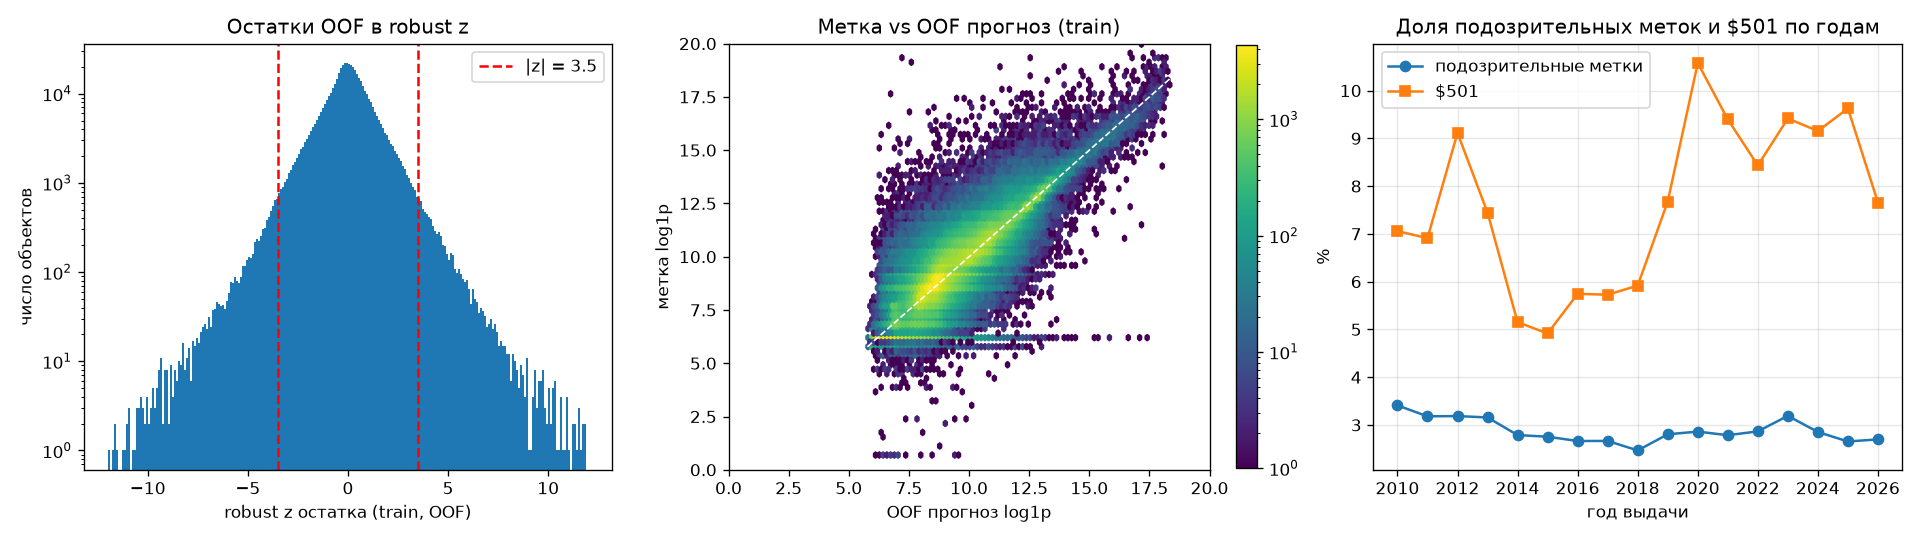

In [12]:
show("labels_cleanlab");
show("labels_service_values");
show("labels_top_values", n=10);
img("labels")

**Интерпретация.**
* OOF-модель имеет RMSLE **0,942 [0,939; 0,945]** (стратифицированный по типу разрешения bootstrap) — того же уровня, что baseline на val, поэтому остатки отражают реальную «предсказуемость» меток.
* **Label error rate = 2,86% [2,82; 2,91]** (train, OOF); в val и test — 3,0% и 2,7%, то есть доля подозрительных меток стабильна во времени. Ещё 3,0% меток расходятся с прогнозом больше чем в 10 раз.
* Подозрительные метки сосредоточены в `Bldg-Alter/Repair` (3,3%) против 0,8% у `Bldg-New`.
* **$501 — служебное значение**: 7,7% всех меток (самое частое значение); среди них подозрительных 9,7% против 2,3% у остальных, и на них приходится **24% всех подозрительных меток** train. Кроме того, **61% оценок кратны $1 000** (38% — $5 000): оценки округляются, то есть метка заведомо содержит шум квантования.
* cleanlab согласуется с robust z лишь частично (пересечение худших 54%, Spearman 0,51): OUTRE учитывает и величину самой метки, поэтому помечает также крайние, но правдоподобные значения. Основным критерием остаётся robust z (как и было решено).

In [13]:
show("labels_worst20", cols=["PERMIT_NBR", "PERMIT_TYPE", "SUB_TYPE", "SQUARE_FOOTAGE", "VALUATION", "OOF прогноз $", "z", "WORK_DESC"]);

,PERMIT_NBR,PERMIT_TYPE,SUB_TYPE,SQUARE_FOOTAGE,VALUATION,OOF прогноз $,z,WORK_DESC
0,17010-10008-01465,Bldg-Alter/Repair,Commercial,NaN,2.625e+08,1450,18.07,"SUPPLEMENTAL TO PERMIT #17010-10000-01465 FOR EARLY START PERMIT BETWEEN TOP OF ISOLATOR COLUMNS, GROUND LEVEL SLAB THROUGH LEVEL 2 SLAB..."
1,12010-10007-01270,Bldg-Alter/Repair,Commercial,NaN,1.911e+08,2077,17.05,"Structural frame erection permit to construct core and shell of structural framing from ground floor to 26th floor (elev. =586'-0"") of t..."
2,19010-10000-02232,Bldg-New,Commercial,4.115e+04,501,3.363e+07,-16.65,NEW CONSTRUCTION OF LAX AIRPORT POLICE DIVISION SHOOTING RANGE BUILDING W/ ATTACHED PARKING STRUCTURE ACCOMODATING SITE AND FLEET PARKING.
3,09014-10003-01473,Bldg-Alter/Repair,Commercial,NaN,4.912e+07,840,16.38,TO CAPTURE SCHOOL DISTRICT FEE AND REMAINING PERMIT FEE FOR PERMIT NUMBER 09014-10000-01473
4,10010-10000-02362,Bldg-New,Commercial,6.793e+04,501,2.534e+07,-16.23,"NEW CENTRAL UTILITY PLANT FOR LAX , TYPE I-B CONSTRUCTION, 4 STORY, 47,930 SF"
5,05010-10006-05187,Bldg-New,Apartment,1.641e+05,501,1.732e+07,-15.66,"TO CORRECT PERMIT NUMBER 05010-1000-05187 WORK DESCRIPTION TO ""NEW 21-STORY CONDO BUILDING CORE AND SHELL ONLY. PERMIT WILL INCLUDE 1S..."
6,17010-10000-01113,Bldg-New,Commercial,4.093e+04,501,7.798e+06,-14.47,ZONING REVIEW ONLY FOR NEW MIXED USE RESIDENTIAL(with 49 units apartment in Los Angeles site). Zoning check only.clearance and applica...
7,11010-10000-00257,Bldg-New,Commercial,1.593e+04,501,7.493e+06,-14.41,NEW REPLACEMENT MAINTENANCE BUILDING (WITH HVAC COOLING TOWERS) FOR LAX CTA CENTRAL UTILITY PLANT (CUP) PROJECT.
8,18016-10033-19512,Bldg-Alter/Repair,Commercial,NaN,1.011e+07,826,14.04,**LAX*** SUPPLEMENTAL PERMIT TO 18016-10000-19512 FOR DEFERRED DESIGN ITEM-- ANCHORAGE( BRACING/SUPPORT) OF BAGGAGE HANDLING CONVEYOR ...
9,16010-10002-05912,Bldg-Alter/Repair,Apartment,NaN,6.44e+06,571,13.91,SUPP. PERMIT TO CAPTURE CORRECT CINSTRUCTION COST


**Ручной разбор 20 худших меток (train).** Почти все случаи объясняются тем, что **метка не описывает работы, к которым относятся признаки**:

| Категория | Строки таблицы (сверху вниз) | Кол-во | Что видно |
|---|---|---|---|
| Служебное значение $501 у крупного нового строительства | 3, 5, 6, 7, 8, 11, 13 | 7 | Площадь 16–164 тыс. кв. футов, прогноз $4–34 млн, метка $501; часть — «to correct permit number», «zoning review only», supplemental |
| Заглушка $1 | 14, 16, 17 | 3 | «no change in valuation», deferred submittal, ремонт кухни за $1 |
| Административное разрешение со стоимостью **всего проекта** | 1, 4, 9, 10, 15, 19 | 6 | «to capture school district fee», «to collect … fees, no actual work», «capture correct construction cost», продление разрешения: метка $3,7–262 млн при отсутствии собственных работ |
| Правдоподобная метка, ошибка модели | 2, 12, 18, 20 | 4 | Крупные работы в аэропорту LAX и каркас 26-этажного здания, оформленные как Alter/Repair без площади: модель не видит масштаба |

Итого **16 из 20** — проблемы метки (несоответствие метки и признаков), **4 из 20** — пределы модели.
Вывод: основная часть «шума меток» — не случайные опечатки, а **систематические практики оформления** (служебные суммы, перенос стоимости всего проекта на дополнительное разрешение).

## 8. Репрезентативность и сдвиг распределений (train vs test)

* **MMD** (RBF, медианная эвристика; несмещённая U-статистика) на подвыборках по 5 000 объектов: permutation p-value (1 000 перестановок) и стратифицированный bootstrap CI (B = 2000). Представления: признаки без времени; признаки со временем; эмбеддинги [CLS] baseline-модели. **Контроль** — две случайные половины train.
* **C2ST**: классификатор (логистическая регрессия и MLP) отличает train от test; ROC-AUC на отложенной половине (20 000 + 20 000), BCa-интервал со стратификацией по классу. 0,5 — неразличимы.
* KS-тест для цели и динамика по годам.

,сравнение,представление,mmd2_u,ci_low,ci_high,p_value,perm_q95
0,train vs test,признаки без времени,0.02201,0.02035,0.02381,0.000999,6.223e-05
1,train vs test,признаки с временем,0.03113,0.02955,0.03287,0.000999,5.96e-05
2,train vs test,эмбеддинги [CLS] baseline,0.004759,0.004273,0.005341,0.000999,0.0001984
3,train vs val,признаки без времени,0.01686,0.01548,0.0184,0.000999,5.724e-05
4,train vs val,признаки с временем,0.02616,0.02481,0.02765,0.000999,5.332e-05
5,train vs val,эмбеддинги [CLS] baseline,0.003812,0.003417,0.004328,0.000999,0.0001987
6,train_A vs train_B,признаки без времени,3.481e-05,-4.568e-05,0.0001282,0.09391,4.496e-05
7,train_A vs train_B,признаки с временем,2.813e-05,-4.817e-05,0.000118,0.1349,4.388e-05
8,train_A vs train_B,эмбеддинги [CLS] baseline,-3.147e-05,-0.0002015,0.0003589,0.5165,0.0002047


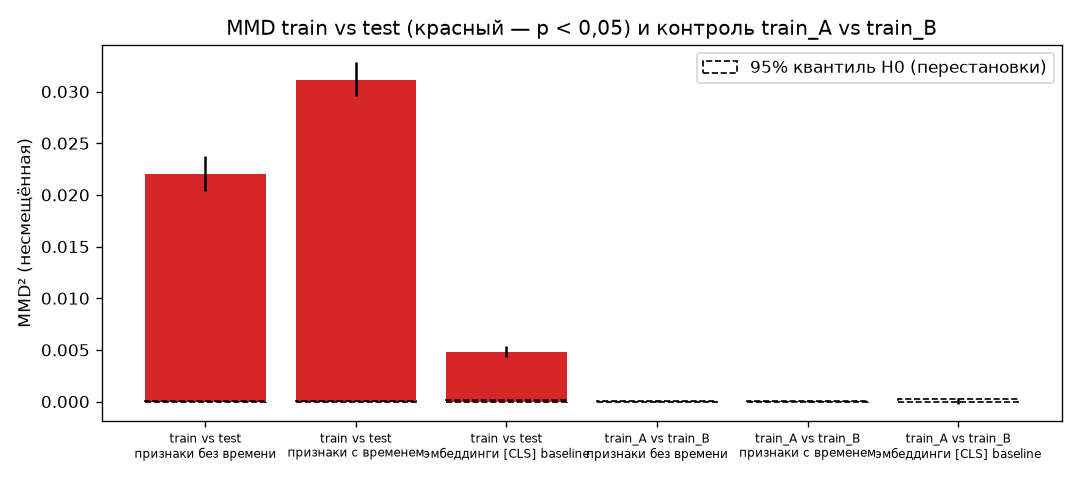

,сравнение,время,классификатор,auc,auc_ci_low,auc_ci_high,accuracy
0,train vs test,нет,логистическая регрессия,0.8932,0.8891,0.8975,0.8095
1,train vs test,нет,MLP (64),0.9216,0.9181,0.9251,0.8383
2,train vs test,да,логистическая регрессия,0.9929,0.9918,0.9938,0.9786
3,train vs test,да,MLP (64),0.9899,0.9885,0.9911,0.9667
4,train vs val,нет,логистическая регрессия,0.826,0.82,0.8316,0.7476
5,train vs val,нет,MLP (64),0.8644,0.8593,0.8692,0.7795
6,train vs val,да,логистическая регрессия,0.9902,0.9889,0.9913,0.9744
7,train vs val,да,MLP (64),0.985,0.9833,0.9866,0.9613
8,train_A vs train_B,нет,логистическая регрессия,0.5008,0.493,0.5091,0.5017
9,train_A vs train_B,нет,MLP (64),0.503,0.4949,0.5113,0.4994


In [14]:
show("shift_mmd", cols=["сравнение", "представление", "mmd2_u", "ci_low", "ci_high", "p_value", "perm_q95"]);
img("shift_mmd")
show("shift_c2st", cols=["сравнение", "время", "классификатор", "auc", "auc_ci_low", "auc_ci_high", "accuracy"]);

**Интерпретация MMD и C2ST.**
* Контроль работает: две случайные половины train неразличимы (MMD² ≈ 0, p = 0,09–0,52; C2ST AUC 0,50 [0,49; 0,51]).
* **Train и test различимы очень сильно**: MMD²_u = 0,022 [0,020; 0,024] при 95%-м квантиле нулевого распределения 0,0001 (p ≤ 0,001); C2ST без признаков времени — **ROC-AUC 0,89 [0,89; 0,90]** (логрег) и **0,92 [0,92; 0,93]** (MLP). С признаками времени AUC ≈ 0,99 — это тривиально: год выдачи отличается по построению split.
* Даже соседний по времени val отличается от train (AUC 0,83–0,86).
* В пространстве эмбеддингов [CLS] сдвиг тоже значим (p ≤ 0,001), но относительно меньше (MMD² 0,0048): модель частично «сглаживает» различия, не важные для прогноза.

Какие признаки дают сдвиг — C2ST по каждой группе признаков отдельно:

,группа признаков,value,ci_low,ci_high,ci_method
0,число: issue_year,0.9736,0.9714,0.9758,BCa
1,текст: SVD(64),0.8645,0.8598,0.8692,BCa
2,категория: CNC,0.7393,0.7322,0.7457,BCa
3,категория: CT,0.6866,0.6794,0.6934,BCa
4,категория: ZONE,0.6312,0.6232,0.6387,BCa
5,число: desc_len,0.6178,0.6099,0.6254,BCa
6,категория: Business Unit,0.6163,0.6091,0.6235,BCa
7,категория: USE_DESC,0.5809,0.5743,0.5884,BCa
8,категория: zone_base,0.5697,0.562,0.5773,BCa
9,категория: TYPE_LAT_LON,0.5663,0.5617,0.5712,BCa


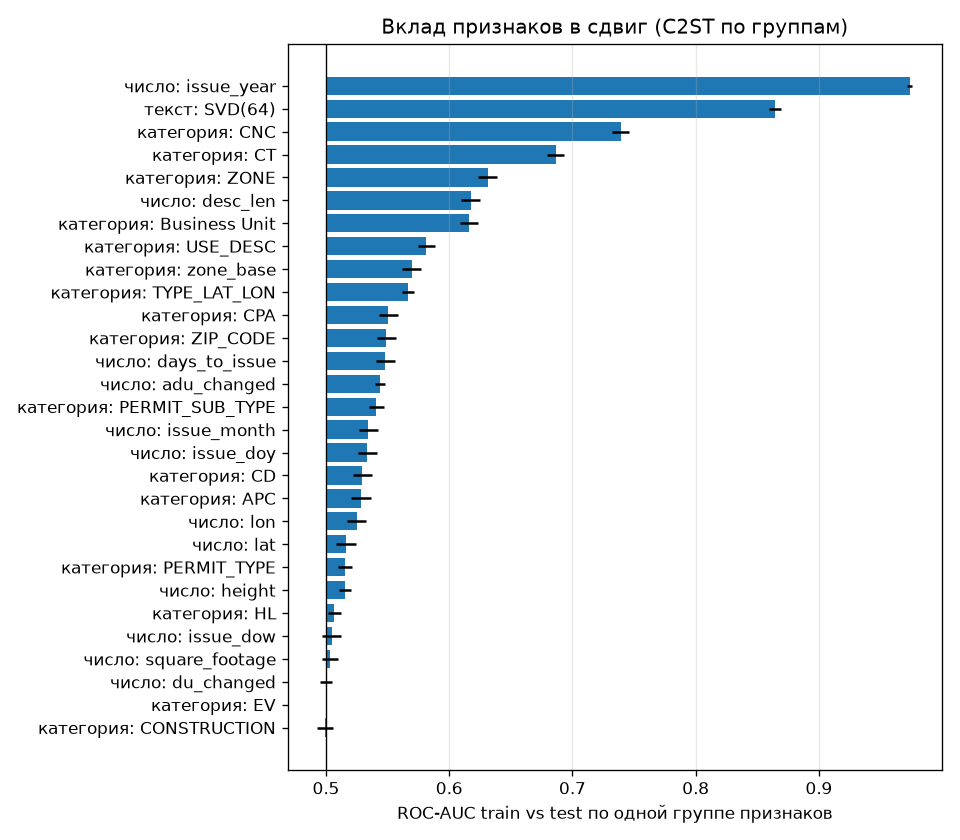

,check,часть,value,ci_low,ci_high
0,текст: «Eplan» (электронная подача),train,0.008655,0.008401,0.008916
1,текст: «Eplan» (электронная подача),val,0.1428,0.1407,0.1449
2,текст: «Eplan» (электронная подача),test,0.1851,0.1828,0.1875
3,текст: номер другого разрешения в тексте,train,0.108,0.1071,0.1089
4,текст: номер другого разрешения в тексте,val,0.1397,0.1376,0.1418
5,текст: номер другого разрешения в тексте,test,0.1473,0.1452,0.1494
6,текст: «supplement»,train,0.09863,0.09781,0.09946
7,текст: «supplement»,val,0.1193,0.1174,0.1213
8,текст: «supplement»,test,0.133,0.131,0.1351
9,текст: шаблон re-roof «Class A or B»,train,0.1465,0.1456,0.1475


In [15]:
show("shift_feature_c2st", cols=["группа признаков", "value", "ci_low", "ci_high", "ci_method"], n=12);
img("shift_feature_c2st", width=700)
show("shift_drift_facts", cols=["check", "часть", "value", "ci_low", "ci_high"]);

**Причины сдвига** (кроме года выдачи, AUC 0,97):
1. **Текст (AUC 0,86)** — меняется практика оформления: префикс «Eplan» (электронная подача) встречается у 0,9% train и **18,5% test**; шаблон описания перекрытия кровли «Class A or B» — 14,7% → 25,8%; ADU (дополнительные жилые единицы после изменения законов штата) — 4,8% → 13,7%; ссылки на другие разрешения — 10,8% → 14,7%, supplemental — 9,9% → 13,3%.
2. **Административная география**: **13,7% test-объектов имеют census tract, которого нет в train** (новая сетка после переписи 2020 г.), **23,4% — название районного совета (CNC), которого нет в train** (переименования). Для модели это категория `OTHER`.
3. Слабее — зона, длина описания, тип рассмотрения (Business Unit), назначение (USE_DESC).

Структурные признаки (площадь, высота, число квартир, тип конструкции) почти не сдвинуты (AUC ≈ 0,50).

,сравнение,KS D,p_value,медиана log1p a,медиана log1p b
0,train vs val,0.02443,7.362e-46,9.21,9.21
1,train vs test,0.03404,1.491e-88,9.21,9.17
2,val vs test,0.01287,4.449e-08,9.21,9.17


,год,n,медиана $,p25 $,p75 $,доля $501,доля Alter/Repair,доля Commercial,доля Supplemental,пропуск площади,"RMSLE (train: OOF, val/test: baseline)"
0,2010,30654,8500,3000,3e+04,0.07059,0.7995,0.2017,0.1059,0.7354,1.013
1,2011,31410,8000,3000,2.632e+04,0.06909,0.8165,0.202,0.09195,0.7541,0.9956
2,2012,32805,8600,3000,3e+04,0.09114,0.8076,0.202,0.1016,0.7407,0.9931
3,2013,33959,9840,3413,3.5e+04,0.07444,0.7905,0.1967,0.09255,0.7335,0.9918
4,2014,33717,1e+04,4000,4.1e+04,0.05152,0.7608,0.1924,0.07972,0.7082,0.9525
5,2015,37698,1e+04,4400,4e+04,0.04915,0.7649,0.1889,0.08008,0.7192,0.9468
6,2016,39456,1e+04,4000,4e+04,0.05746,0.7703,0.1693,0.08893,0.7276,0.934
7,2017,46194,1e+04,4400,4e+04,0.05726,0.7833,0.1623,0.08858,0.7193,0.9165
8,2018,48939,1.26e+04,4500,4.5e+04,0.05918,0.7783,0.1426,0.09487,0.7043,0.904
9,2019,51569,1.2e+04,4200,4e+04,0.07677,0.7941,0.1451,0.1146,0.7188,0.9207


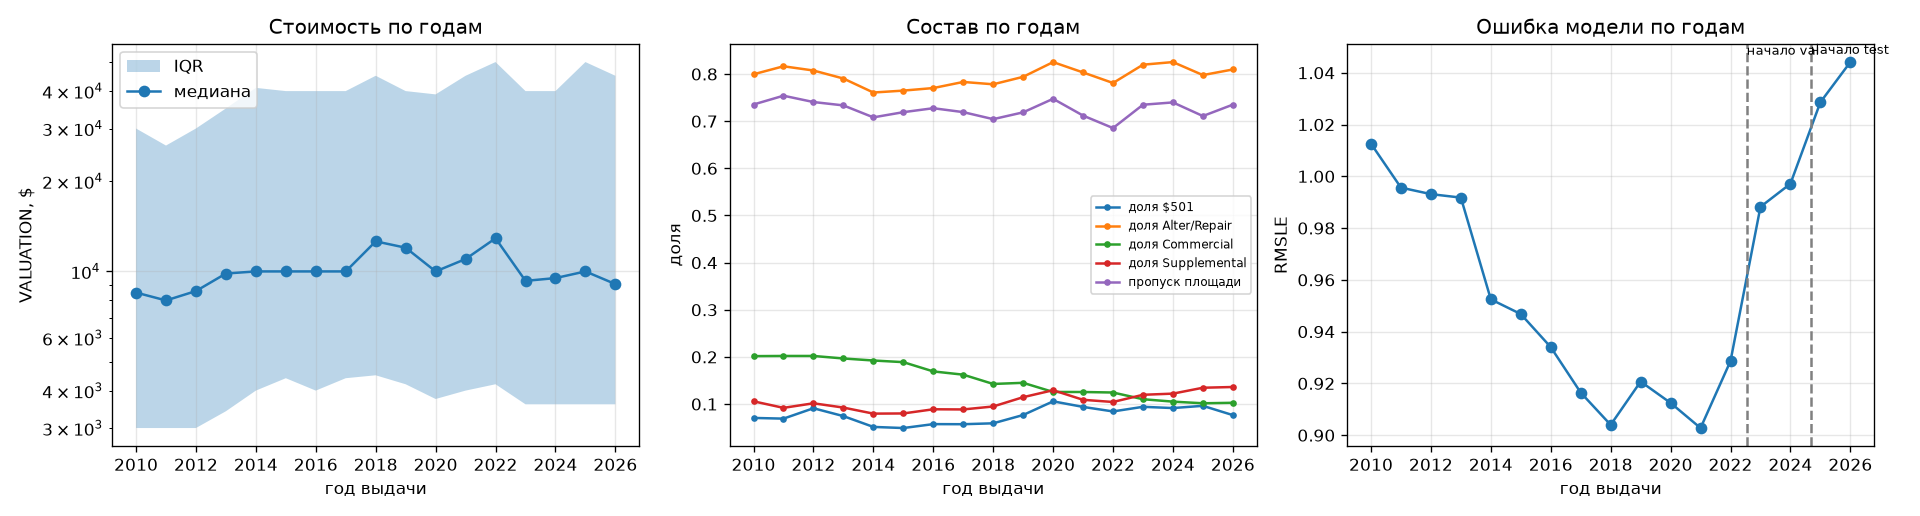

In [16]:
show("shift_ks_target");
show("shift_by_year");
img("shift_by_year")

**Сдвиг цели и динамика.**
* Распределение цели меняется слабо: KS D = 0,034 между train и test (значимо при таком n, но медиана log-стоимости почти та же: 9,21 → 9,17).
* По годам: доля `Commercial` монотонно падает (20% → 10%), доли $501 и дополнительных разрешений растут с 2019–2020 гг.
* Ошибка модели по годам: OOF-ошибка на train снижается от 1,01 (2010) до ≈ 0,90 (2018–2021), а затем **растёт в val/test до 1,03–1,04 (2025–2026)** — прямое проявление сдвига. Деградация умеренная (≈ +0,1 RMSLE), потому что ключевые структурные признаки стабильны.

## 9. Аномалии

* **Критерий 1 — IsolationForest** (300 деревьев, обучен на 200 000 объектов train, признаки без времени): объект аномален, если его score ниже 1-го перцентиля train (в train таких по определению 1%). Дополнительно — встроенный порог `contamination="auto"`.
* **Критерий 2 — выброс цели**: |robust z| > 3,5 для log1p(VALUATION) (медиана и MAD по train).

,часть,check,k,n,value,ci_low,ci_high
0,train,IsolationForest: score ≤ 1-й перцентиль train,4966,496596,0.01,0.009727,0.01028
1,train,IsolationForest: contamination='auto',2995,496596,0.006031,0.00582,0.00625
2,train,"выброс log-цели (|robust z| > 3.5, медиана/MAD train)",2350,496596,0.004732,0.004545,0.004927
3,val,IsolationForest: score ≤ 1-й перцентиль train,2082,106421,0.01956,0.01875,0.02041
4,val,IsolationForest: contamination='auto',1157,106421,0.01087,0.01027,0.01151
5,val,"выброс log-цели (|robust z| > 3.5, медиана/MAD train)",370,106421,0.003477,0.003141,0.003849
6,test,IsolationForest: score ≤ 1-й перцентиль train,1953,106292,0.01837,0.01758,0.0192
7,test,IsolationForest: contamination='auto',1140,106292,0.01073,0.01012,0.01136
8,test,"выброс log-цели (|robust z| > 3.5, медиана/MAD train)",449,106292,0.004224,0.003852,0.004632


,группа test,rmsle,ci_low,ci_high,ci_method,n
0,аномалии IsolationForest,0.5888,0.5455,0.6641,BCa,1953
1,остальные,1.038,1.03,1.046,percentile,104339


,PERMIT_NBR,PERMIT_TYPE,USE_DESC,SQUARE_FOOTAGE,HEIGHT,DU_CHANGED,VALUATION,score,WORK_DESC
0,19016-90000-08602,Bldg-Alter/Repair,Dwelling - Single Family,NaN,NaN,NaN,5.575e+04,-0.3857,"Replace 11 window(s). Same size, location, number, type. Interior kitchen remodel/repair (no changes in walls or openings). Interior bat..."
1,21016-10000-13786,Bldg-Alter/Repair,Telecommunication Transmitter - wireless,NaN,NaN,NaN,5e+04,-0.3975,"MODIFICATION TO AN EXISTING WIRELESS FACILITY-ROOFTOP SITE. REMOVING AND REPLACING (3) ANTENNAS, ADDING 3 RADIOS, AND ADDING BATTERY & R..."
2,23016-10000-22684,Bldg-Alter/Repair,Apartment,NaN,NaN,NaN,6e+04,-0.4032,Eplan: Soft-Story seismic retrofit per LABC Chapter 93: Mandatory soft-story retrofit per LABC Chapter 93 under Ordinance 183893 and Ord...
3,11016-20000-08979,Bldg-Alter/Repair,Dwelling - Single Family,NaN,NaN,NaN,4700,-0.3857,Re-roof with Class A or B material weighing less than 6 pound per sq. ft.
4,14014-70000-05333,Bldg-Alter/Repair,Dwelling - Single Family,NaN,NaN,NaN,1.5e+04,-0.4146,"Alteration to existing single family dwelling to convert closet into a powder room, remodel kitchen, and raise the ceiling at master bed..."
5,23016-90000-41998,Bldg-Alter/Repair,Dwelling - Single Family,NaN,NaN,NaN,7200,-0.386,Re-roof with Class A or B roof covering material weighing less than 6 pounds per sq. ft. over existing solid sheathing 36 Squares. Class...
6,20016-90000-08708,Bldg-Alter/Repair,Apartment,NaN,NaN,NaN,8000,-0.3761,Reroof with 40 sqrs COMP SHINGLE roofing. Existing solid sheathing.Re-roof with Class A or B material weighing less than 6 pounds per sq...
7,19016-10000-40334,Bldg-Alter/Repair,Office,0,NaN,NaN,2e+04,-0.4029,CHANGE OF USE FROM (E) MEDICAL LABORATORY TO OFFICE. CONVERT OFFICE INTO A NEW SINGLE ACCOMMODATION RESTROOM AND MINOR INTERIOR REMODEL...
8,20010-20000-04205,Bldg-New,Dwelling - Single Family,2599,25.75,1,3.48e+05,-0.4803,(TR 71866-01 PVSP-SUBAREA 2) PROPOSE TWO STORY SFD WITH ATTACHED GARAGE_PLAN 2A_ [BUILDING SHALL BE FULLY SPRINKLER THROUGH OUT WITH NFP...
9,19010-10000-04018,Bldg-New,Dwelling - Single Family,1185,21.5,1,2.2e+05,-0.4268,NEW SINGLE FAMILY DWELL W/ATTACHED 6 CAR GARAGE 2ND STORY 1185 SF UNIT


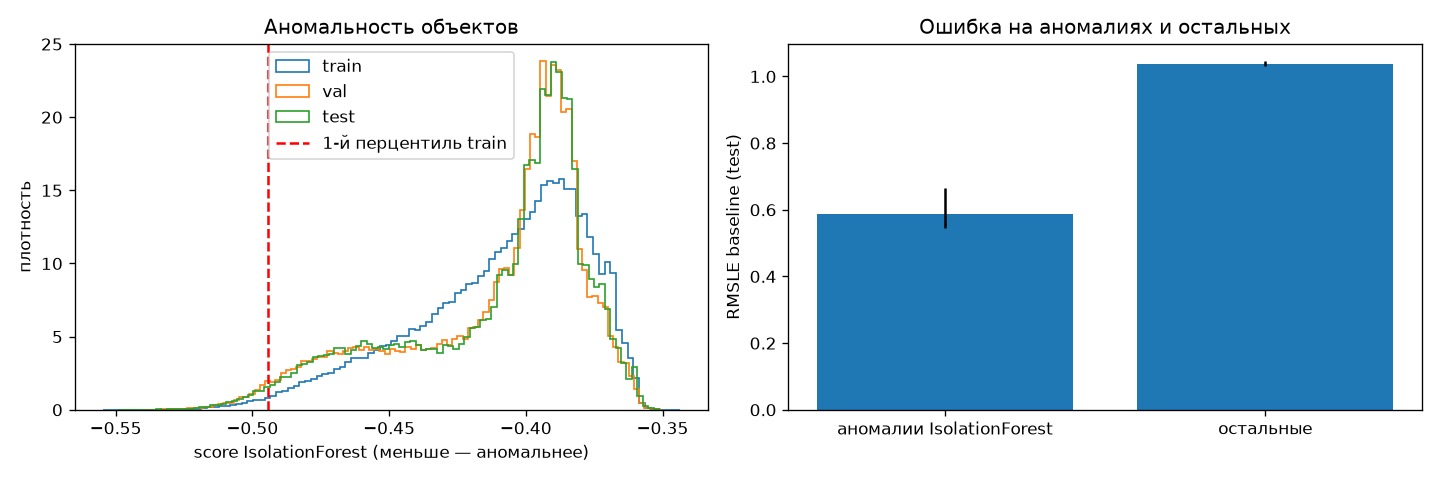

In [17]:
show("anomalies", cols=["часть", "check", "k", "n", "value", "ci_low", "ci_high"]);
show("anomalies_error");
show("anomalies_top15", n=10);
img("anomalies")

**Интерпретация.**
* В test **1,84% [1,76; 1,92]** объектов аномальны по критерию train (ожидалось 1% при отсутствии сдвига) — ещё одно подтверждение сдвига.
* Выбросы цели редки: 0,42% в test (очень дешёвые и очень дорогие работы).
* Неожиданно: **на аномалиях IsolationForest ошибка модели ниже** (RMSLE 0,59 [0,55; 0,66] против 1,04). Просмотр топ-аномалий показывает, что «изолированными» оказываются строки с **длинными шаблонными описаниями** (стандартный текст перекрытия кровли, замена окон, сейсмоусиление): они экстремальны по SVD-компонентам текста, но хорошо предсказуемы. Аномальность в пространстве признаков ≠ трудность для модели; трудные объекты определяются качеством меток (раздел 7).

## 10. Итоговая таблица (формат методички)

In [18]:
summary = pd.read_csv(R / "summary.csv")
display(summary)

,Свойство,Метрика,Значение,95% CI,Метод CI,Интерпретация
0,Полнота,доля пропущенных ячеек (используемые признаки),23.71,[23.69; 23.72],percentile,"в %; пропуски в основном структурные (площадь, высота, конструкция заполняются для New/Addition)"
1,Полнота,доля объектов с ≥ 1 пропуском (используемые признаки),99.94,[99.93; 99.94],wilson,в %; почти у каждого объекта есть пропуск → модель должна работать с пропусками (эмбеддинг «пропуск»)
2,Полнота,пропуск площади у Bldg-New,2.09,[1.97; 2.20],wilson,в %; для нового строительства площадь почти всегда заполнена
3,Валидность,доля объектов с ≥ 1 нарушением формата/диапазона/правил,14.04,[13.97; 14.12],wilson,в %; основной вклад — VALUATION ≤ 0 и нулевая площадь
4,Валидность,VALUATION ≤ 0 (невалидная метка),6.64,[6.59; 6.70],wilson,в %; строки исключены из обучения
5,Валидность,SQUARE_FOOTAGE ≤ 0 среди заполненных,16.33,[16.16; 16.49],wilson,в %; ноль используется как «не указано» — шум в важном признаке
6,Уникальность,duplicate rate (дубли без учёта ID),0.061,[0.056; 0.067],wilson,в %; точных дублей нет (PERMIT_NBR уникален); дубли удалены до split
7,Уникальность,"near-duplicate rate (APN + MinHash Jaccard ≥ 0,9 + стоимость ±10%)",0.38,[0.36; 0.39],wilson,в %; повторные разрешения на те же работы — часть может попасть в разные части split
8,Уникальность,доля дополнительных разрешений (Supplemental),10.69,[10.62; 10.76],wilson,"в %; связаны с основным разрешением, стоимость часто служебная ($501)"
9,Train-test leakage,test: точная копия входа модели в train,0.02,[0.01; 0.03],wilson,"в %; типовые разрешения с одинаковым описанием — не утечка объекта, но завышают качество"


## 11. Вывод: какие свойства данных повлияют на ПР2–ПР4

Качество данных — многомерное свойство. Ключевые находки и их последствия:

| Свойство | Находка | Влияние |
|---|---|---|
| Качество меток | 2,9% подозрительных меток; $501 у 7,7% (служебное значение; у 45% дополнительных разрешений); 61% оценок округлены; стоимость проекта на административных разрешениях | Нижнюю границу RMSLE задаёт шум меток: 4% строк дают ≈ 40% квадратичной ошибки baseline. **ПР2:** baseline M(0) уже «зашумлён», а RMSLE чувствительна к хвосту — изменения от шума признаков сравниваем **парным** bootstrap на одних объектах и обсуждаем практическую величину (при n ≈ 10⁵ CI очень узкие). **ПР4:** у шумных меток большой loss и у members, если модель их не запомнила, — loss-атака будет путать «трудные» и «чужие» объекты |
| Полнота | 24% пропущенных ячеек, пропуски структурные; у Alter/Repair (80% данных) площадь и высота почти всегда пусты | **ПР2:** шум «пропуски» в структурных признаках влияет в основном на New/Addition; для Alter/Repair главный вход — текст, поэтому текстовые искажения (опечатки, удаление слов) должны быть одним из типов шума; результаты стоит показывать по подгруппам |
| Валидность | 14% строк нарушают правила; площадь = 0 у 16% заполненных; высота до 41 000 футов | **ПР2:** «обнуление» площади — естественный тип порчи, уже присутствующий в данных. **ПР3:** validity constraints задаём по предметной области (площадь > 0, высота ≤ 1100 футов, DU_CHANGED ≤ 2 для «1 or 2 Family», категории из словаря), а не по эмпирическому диапазону train |
| Сдвиг | C2ST AUC 0,89–0,92 без времени; новые текстовые шаблоны (Eplan), новые census tract (13,7%), переименованные CNC (23%); ошибка растёт к 2026 г. | Test — «будущее», часть деградации качества объясняется сдвигом, а не шумом. **ПР2:** кривые устойчивости строим относительно M(0) на том же test. **ПР4:** **хронологические val/test нельзя брать как non-members** — атака будет различать периоды, а не членство (C2ST уже даёт AUC 0,83–0,92). Нужны non-members из того же распределения, что и members |
| Leakage | Копий объектов между частями почти нет (0,02%), но 43% test-участков есть в train | **ПР4:** выбор privacy unit критичен: при единице «участок» members и non-members пересекаются по участкам; при единице «строка» повторные разрешения на тот же участок дают модели «подсказку» |
| Баланс | IR = 201, хвост ≥ $10M — 0,2%; доля Commercial падает с 16,5% до 10,1% | Оценки на дорогих объектах и Commercial наименее надёжны; в ПР2–ПР3 метрики стоит дополнительно давать по подгруппам |
| Аномалии | 1,8% аномалий в test (против 1% в train); аномалии по признакам — шаблонные тексты, ошибка на них ниже | Аномальность входа не совпадает с трудностью: для поиска аномальных **оценок** (сценарий применения) нужен анализ остатков, как в разделе 7 |
| Уникальность | Дубли без ID 0,06%, близкие дубли 0,38% (повторные типовые разрешения) | На метрики почти не влияют; для ПР4 повторные разрешения на тот же участок — возможный источник информации о членстве |

**Ограничения анализа.** OOF-модели используют препроцессор, обученный на всём train (метки при этом не используются). Порог |z| > 3,5 выявляет только грубые расхождения; округление оценок до $1 000 в эту долю не входит. Обучение воспроизводимо бит-в-бит при фиксированном seed (проверено двумя запусками); при другом seed val RMSLE меняется примерно на 0,01, поэтому различия моделей меньше этой величины не считаем содержательными.